In [40]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import tqdm.auto as tqdm
from numba import njit, prange


mpl.rc('figure', dpi = 150)
mpl.rc('figure', figsize = (8, 4))

# Intento 1 modelo

In [41]:
# Definicion de variables
# Los valores 1 son provisionales; deben sustituirse antes de simular.
# Unidades SI. Las variables derivadas se recalculan en las celdas siguientes.

# Temperaturas y propiedades del acero
T_R = 1  # Temperatura del termopar de control (K).
T_g = 1  # Temperatura del gas protector (K).
T_m = 1  # Temperatura media de las superficies enfrentadas (K).
rho = 1  # Densidad de la bobina de acero (kg/m^3).
c = 1  # Calor especifico del acero (J/(kg K))
epsilon = 0.08554  # Emisividad de la bobina de acero (adimensional).
lambda_z = 1  # Conductividad termica axial (W/(m K)).
lambda_s = 1  # Conductividad termica del acero (W/(m K)).
lambda_O = 1  # Conductividad termica de la capa de oxido (W/(m K)).

# Gas protector y transferencia por conveccion
lambda_g = 1  # Conductividad termica del gas protector (W/(m K)).
u_g = 1  # Velocidad del gas protector (m/s).
mu_g = 1  # Viscosidad dinamica del gas protector (Pa s).
rho_g = 1  # Densidad del gas protector (kg/m^3).
D = 1  # Diametro de la seccion de flujo (m).
L = 1  # Longitud de circulacion del fluido (m).
h_N = 1  # Coeficiente convectivo sobre la placa superior de la bobina (W/(m^2 K)).
h_E = 1  # Coeficiente convectivo entre la superficie exterior y la cubierta interior (W/(m^2 K)).
psi = 1  # Factor de intensificacion de la conveccion por vortices (adimensional).
xi = 1 # Factor de flujo entre capas convectivas
chi = 1  # Factor aplicado a h para T_g <= 800 K en el codigo para considerar radiacion. 
inv_zeta = 0.909  # Coeficiente de atenuacion del caudal, 1/zeta (adimensional).
zeta = 1 / inv_zeta  # Inverso del coeficiente de atenuacion del caudal (adimensional).
Q = 1  # Caudal volumetrico total del gas protector (m^3/s).

# Contacto entre capas y radiacion
P = 8e6  # Esfuerzo de compresion entre capas (Pa), equivalente a 8 MPa.
H = 1133.86e6  # Dureza de los materiales en contacto (Pa), equivalente a 1133.86 MPa.
eta = 1  # Factor de correccion de resistencia termica debido a emulsiones (adimensional).
sigma = 5.670374419e-8  # Constante de Stefan-Boltzmann (W/(m^2 K^4)).
sigma_P = 3.2215e-6  # Rugosidad superficial del acero (m), equivalente a 3.2215 micrometros.
theta = 1  # Angulo de la pendiente superficial media (rad); el modelo utiliza np.tan(theta).

# Resistencias termicas por unidad de area
R_S_half = 1  # Resistencia de medio espesor de acero (m^2 K/W); se calcula despues.

# Geometria y discretizacion
h = 10  # Altura del dominio (m), valor existente; el codigo reutiliza h para conveccion.
r = 10  # Radio maximo del dominio (m), valor existente.
tau = 10  # Duracion de la simulacion (s), valor existente.
n_steps_h = 100  # Numero de nodos axiales, valor existente.
n_steps_r = 100  # Numero de nodos radiales, valor existente.
n_steps_t = 100  # Numero de instantes de tiempo, valor existente.
dr = 1  # Paso radial (m); se calcula a partir de R.
dz = 1  # Paso axial (m); se calcula a partir de Z.
dt = 1  # Paso temporal (s); se calcula a partir de T.
M = 1  # Radio maximo de la bobina (m), segun la nomenclatura proporcionada.
N = 1  # Radio minimo de la bobina (m), segun la nomenclatura proporcionada.
S = 1  # Espesor de la tira de acero que forma la bobina (m).
b = 1  # Separacion entre capas de la tira de acero (m); se calcula despues.
b_O = 1  # Espesor de la capa de oxido (m).
coNum = 1  # Numero de bobinas de acero (entero, adimensional).


AttributeError: AxesImage.set() got an unexpected keyword argument 'colormap'

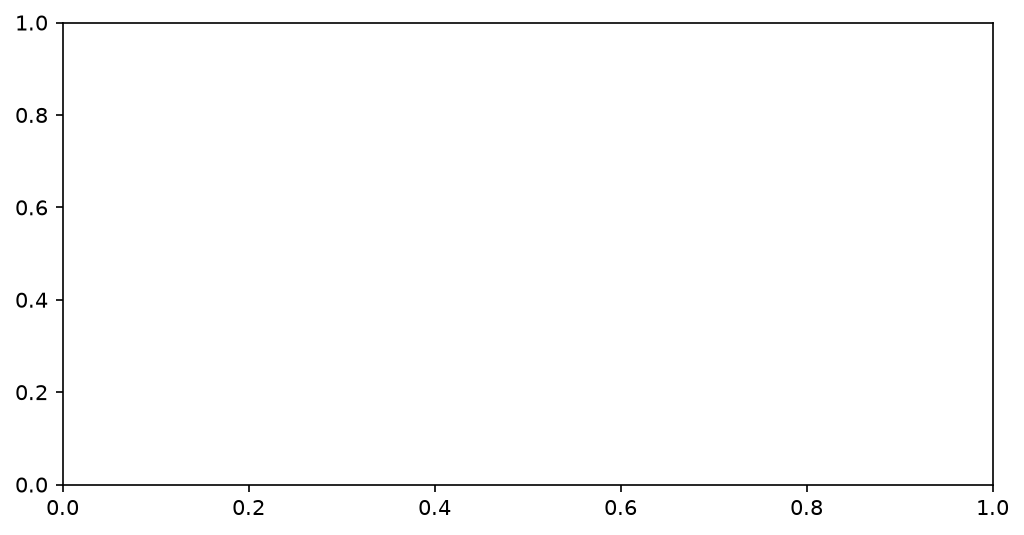

In [ ]:
h = 10
r = 10
tau = 10

n_steps_h = 100
n_steps_r = 100
n_steps_t = 100

Z = np.linspace(0, h, n_steps_h)
R = np.linspace(0, r, n_steps_r)
T = np.linspace(0, tau, n_steps_t)

dz = Z[1] - Z[0]
dr = R[1] - R[0]
dt = T[1] - T[0]

T_total = np.zeros((len(Z), len(R), len(T)))    

# Coeficiente convectivo

phi = P / (H + P)

h = 0.023 * phi * u_g ** 0.8 / D **0.2 * lambda_g * (mu_g / rho_g) ** -0.8 * (1 + (D / L)**0.7)

if T_g > 800:
    k = h
else:
    k = chi * h

# Distribucion del flujo de gas protector

fd3 = 1/(2+ coNum)
fd2 = xi * fd3
fd1 = xi * fd2

Qcp1 = Q * fd1
Qcp2 = Q * (1 - fd1) * fd2
Qcp3 = Q * (1 - fd1) * (1 - fd2) * fd3
Qtop = Q * (1 - fd1) * (1 - fd2) * (1 - fd3)

# Conductividad radial

R_S_half = S / (2 * lambda_s)

R_O = b_O / lambda_O

R_R = (2 - epsilon) / (
    4 * (1 - phi) * epsilon * sigma * T_m**3
)

R_G = b / ((1 - phi) * lambda_g)

R_D = (
    sigma_P / (1.13 * lambda_s * np.tan(theta))
) * phi**(-0.94)
b = 42.7 * 1e-06 * np.exp(-5 * 1e-02)

if T_g >= 800:
    lambda_r = (S + b + b_O) / (
        S / lambda_s
        + b_O / lambda_O
        + (
            4 * (1 - phi) * epsilon * sigma * T_m**4 / (2 - epsilon)
            + (1 - phi) * lambda_g / b
            + 1.13 * lambda_s * np.tan(theta) * phi**0.94 / sigma_P
        )**(-1)
    )
else:
    lambda_r = eta * (S + b) / (
        S / lambda_s
        + (
            4 * (1 - phi) * epsilon * sigma * T_m**4 / (2 - epsilon)
            + (1 - phi) * lambda_g / b
            + 1.13 * lambda_s * np.tan(theta) * phi**0.94 / sigma_P
        )**(-1)
    )

# Region interior

T_int = T_total[1:-1, 1:-1]

for i in range(len(T) - 1):
    for m in range(len(Z)):
        for n in range(len(R)):
            if 1 <= m <= len(Z - 1) and 1 <= n <= (len(R) - 1):
                T_total[m, n, i + 1] = ( (1 - (2*lambda_r*dz*dt) / (rho*c*dr) 
                                    - (lambda_z*dr*dt)/(rho*c*dz))*T_total[m, n, i] 
                                    + dt/(rho*c) * ( lambda_r*dz/dr * (T_total[m+1, n, i] 
                                    + T_total[m-1, n, i]) + lambda_z *dr/dz * (T_total[m, n+1, i] 
                                    + T_total[m, n-1, i])) )
            
            elif (
                (m == 0 and 1 <= n <= len(R) - 1)
                or (m == len(Z) and 1 <= n <= len(R) - 1)
                or (n == 0 and 1 <= m <= len(Z) - 1)
                or (n == len(R) and 1 <= m <= len(Z) - 1)
            ):
                T_total[m, n, i + 1] = ((1 - 2 * lambda_r * dz * dt / (rho * c * dr)
                                        - lambda_z * dr * dt / (rho * c * dz)
                                        - h_N * dr * dt / (rho * c)) * T_total[m, n, i]
                                        + dt / (rho * c) * (lambda_r * dz / dr * (T_total[m + 1, n, i] 
                                        + T_total[m - 1, n, i]) + lambda_z * dr / dz * T_total[m, n - 1, i]
                                        + h_N * dr * T_g) )
            
            elif (
                (m == 0 and n == 0)
                or (m == 0 and n == len(R) - 1)
                or (m == len(Z) - 1 and n == 0)
                or (m == len(Z) - 1 and n == len(R) - 1)
            ):
                T_total[m, n, i + 1] = ((1 - lambda_r * dz * dt / (rho * c * dr)
                                         - lambda_z * dr * dt / (rho * c * dz)
                                         - (h_E * dz + h_N * dr) * dt / (rho * c)) * T_total[m, n, i]
                                        + dt / (rho * c) * (lambda_r * dz / dr * T_total[m - 1, n, i]
                                        + lambda_z * dr / dz * T_total[m, n - 1, i]
                                        + (h_E * dz + h_N * dr) * T_g) )

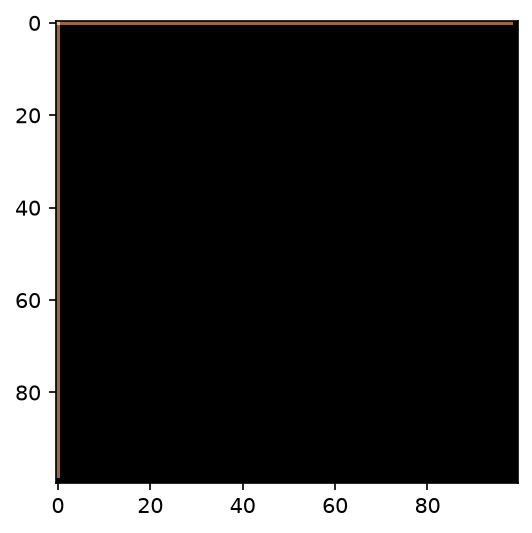

In [53]:
plt.imshow(T_total[:, :, 1], 'copper')
plt.show()